# WeatherVision: Multimodal Weather Classification
### Assignment 1 Foundation & Assignment 2 Google SigLIP 2 (2025)

**Author:** Rakhman Seidigali · SE-2411 · Computer Vision, Astana IT University  
**Instructor:** Nurym Kaiyrkhan

---

## 1. Project Overview and Research Questions

WeatherVision investigates multi-class outdoor image classification across four distinct meteorological categories: **Cloudy**, **Rain**, **Shine**, and **Sunrise**. The project bridges classical deep convolutional neural networks with state-of-the-art vision-language foundation models:

- **Assignment 1 (Foundations):**
  1. *Simple CNN*: A lightweight custom architecture with three convolutional blocks trained entirely from scratch.
  2. *MobileNetV2*: Transfer learning via a pre-trained ImageNet-1k backbone with frozen weights and a newly trained linear head.
- **Assignment 2 (State-of-the-Art Multimodal Vision-Language):**
  1. *Google SigLIP 2 (`google/siglip2-base-patch16-224`, 2025)*: A Vision Transformer pre-trained with pairwise sigmoid cross-entropy loss.
  2. *Zero-Shot Classification*: Text-prompt based classification using semantic embeddings without fine-tuning.
  3. *Supervised Linear Probing*: Task-specific adaptation via a linear probe on frozen attention-pooled vision representations.
  4. *Controlled 3-Seed Augmentation Ablation*: Evaluating augmentation stability and feature variance across multiple random seeds.
  5. *Model Explainability*: Spatial patch occlusion tailored for Vision Transformers without gradient access.
  6. *Historical Benchmark*: Comparison with historical ConvNeXt-Tiny results.

### Research Questions
1. **Zero-Shot vs. Supervised:** Can multimodal zero-shot matching compete with supervised task-specific models on specialized weather imagery without seeing any training labels?
2. **Linear Probe Efficiency:** Can a lightweight linear probe (3,076 parameters) trained on frozen 2025 transformer features match or surpass deep convolutional networks (ConvNeXt-Tiny, MobileNetV2)?
3. **Data Augmentation Impact:** Does data augmentation during linear probe training improve test generalisation when features are derived from a foundation vision transformer?
4. **ViT Interpretability:** Can non-gradient patch occlusion reliably ground visual predictions in Vision Transformers where Grad-CAM cannot be straightforwardly applied?

## 2. Environment Setup

This notebook is engineered to run seamlessly in **Google Colab** (with free T4 GPU or CPU runtimes) and in local environments. It automatically:
1. Clones the repository and installs pinned dependencies if executed on Colab.
2. Selects the fastest available execution device (`cuda`, `mps`, or `cpu`).
3. Verifies official pre-trained checkpoints and assets.
4. Provides a `RUN_FULL_TRAINING` toggle (default: `False` for instant demonstration and verification; `True` for complete reproduction).

In [1]:
import os
import sys
import subprocess
from pathlib import Path
import json

# Set Matplotlib cache directory
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib_cache"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Detect Google Colab runtime
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    REPO_DIR = Path("/content/WeatherVision")
    if not REPO_DIR.is_dir():
        print("Cloning repository into Colab runtime...")
        subprocess.run(
            ["git", "clone", "https://github.com/commedeschamps/WeatherVision.git", str(REPO_DIR)],
            check=True
        )
    os.chdir(REPO_DIR)
    ROOT = REPO_DIR
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    ROOT = Path.cwd().resolve()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent
        os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import torchvision
import transformers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.utils import select_device, seed_everything, CLASSES, LABELS
from src.siglip2 import MODEL_ID, REVISION, ASSET_DIR
from scripts.download_checkpoints import download_asset

# 1. Device and reproducibility initialization
seed_everything(42)
device = select_device()
print(f"Project root: {ROOT}")
print(f"Device: {device} (CUDA: {torch.cuda.is_available()}, MPS: {torch.backends.mps.is_available()})")
print(f"PyTorch version: {torch.__version__} | Transformers version: {transformers.__version__}")

# 2. Checkpoint and asset verification
with open(ROOT / "configs/checkpoints.json") as f:
    chk_config = json.load(f)

for asset in chk_config["assets"]:
    dest = ROOT / "outputs" / asset["run"] / "best.pt"
    if not dest.is_file():
        print(f"Downloading checkpoint for {asset['run']}...")
        download_asset(asset, dest)

siglip_installed = (ASSET_DIR / "vision/model.safetensors").is_file() and (ASSET_DIR / "provenance.json").is_file()
if not siglip_installed:
    print(f"Installing pinned SigLIP 2 encoder ({MODEL_ID})...")
    from scripts.install_siglip2 import install_siglip_assets
    install_siglip_assets(offline=False)
else:
    print("All Assignment 1, Historical ConvNeXt, and SigLIP 2 assets verified.")

# 3. Execution configuration
RUN_FULL_TRAINING = False
print(f"Mode: {'FULL TRAINING REPRODUCTION' if RUN_FULL_TRAINING else 'FAST DEMONSTRATION & VERIFICATION'}")

/Users/rakhman/Desktop/assignment2-cv/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /Users/rakhman/Desktop/assignment2-cv
Device: mps (CUDA: False, MPS: True)
PyTorch version: 2.10.0 | Transformers version: 4.57.6
All Assignment 1, Historical ConvNeXt, and SigLIP 2 assets verified.
Mode: FAST DEMONSTRATION & VERIFICATION


## 3. Dataset Acquisition and Exploratory Analysis

The dataset is derived from Gbeminiyi Ajayi's *Multi-class Weather Dataset* (2018, CC BY 4.0), mirrored via PerceptiLabs (`commit ad78ac8fcf1b1aae229ca6e5310aa75b06783787`).

### Data Cleaning and Duplicate Handling
- **Original Audit:** 1,123 photographs were identified and audited across four classes.
- **Deduplication:** Conservative perceptual hashing (pHash, dHash) and byte-level SHA-256 identified **26 exact duplicate photographs**, which were permanently removed.
- **Group Splitting:** The remaining **1,097 clean photographs** were partitioned into 1,011 perceptual groups. All duplicate or near-duplicate pairs were assigned strictly to the same partition, preventing train/test data leakage.
- **Split Distribution:** ~70% Train (768 images), ~15% Validation (164 images), ~15% Test (165 images).

Total verified photographs: 1097
Duplicates removed during audit: 26
Independent perceptual groups: 1011


split,train,val,test,Total
label,,,,
cloudy,204,43,44,291
rain,143,31,31,205
shine,175,37,37,249
sunrise,246,53,53,352


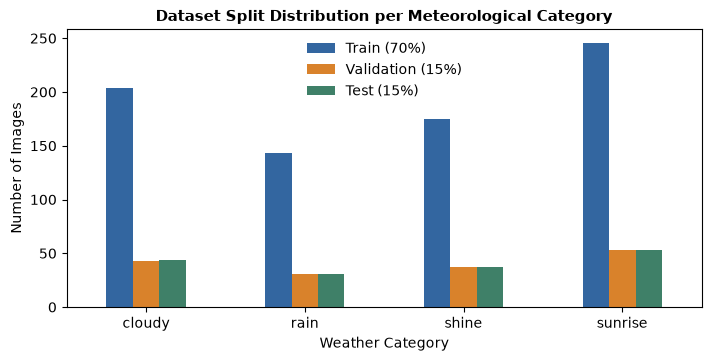

In [2]:
manifest_path = ROOT / "data/manifest.csv"
manifest = pd.read_csv(manifest_path)
stats = json.loads((ROOT / "data/statistics.json").read_text())

print(f"Total verified photographs: {len(manifest)}")
print(f"Duplicates removed during audit: {stats['exact_duplicates_removed']}")
print(f"Independent perceptual groups: {stats['independent_groups']}")

# Class distribution table
dist_table = pd.crosstab(manifest.label, manifest.split).reindex(
    index=CLASSES, columns=["train", "val", "test"]
)
dist_table["Total"] = dist_table.sum(axis=1)
display(dist_table)

# Plot class distribution
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
colors = ["#3366A0", "#D9822B", "#3F8068"]
dist_table[["train", "val", "test"]].plot.bar(ax=ax, color=colors, rot=0)
ax.set_title("Dataset Split Distribution per Meteorological Category", fontsize=11, fontweight="bold")
ax.set_xlabel("Weather Category")
ax.set_ylabel("Number of Images")
ax.legend(["Train (70%)", "Validation (15%)", "Test (15%)"], frameon=False)
plt.show()

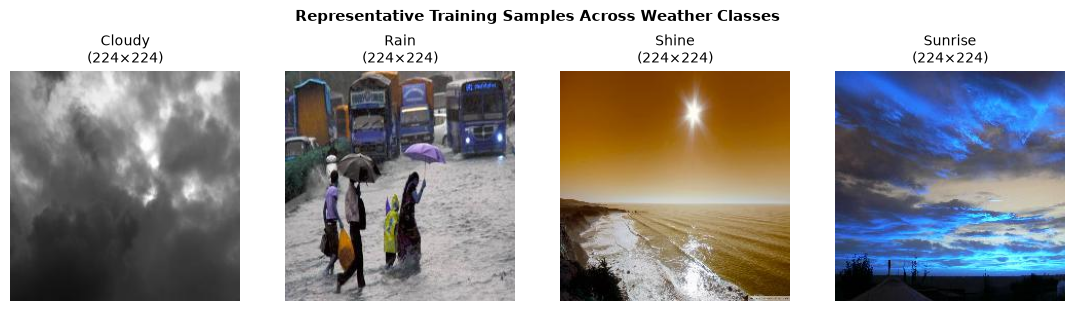

In [3]:
from src.data import open_rgb

fig, axes = plt.subplots(1, 4, figsize=(11, 3), layout="constrained")
for idx, label in enumerate(CLASSES):
    sample_row = manifest[(manifest.label == label) & (manifest.split == "train")].iloc[0]
    img = open_rgb(ROOT / sample_row.path)
    axes[idx].imshow(img)
    axes[idx].set_title(f"{label.capitalize()}\n({img.size[0]}×{img.size[1]})", fontsize=10)
    axes[idx].axis("off")

plt.suptitle("Representative Training Samples Across Weather Classes", fontsize=11, fontweight="bold")
plt.show()

## 4. Preprocessing and Data Splitting

Two distinct preprocessing pipelines are employed:
1. **Assignment 1 & Historical ConvNeXt (Standard PyTorch Transforms):**
   - Resize to $256\times256$ (or $236\times236$ for ConvNeXt).
   - Random resized crop to $224\times224$ (scale: 0.8–1.0, ratio: 0.9–1.1) and horizontal flip ($p=0.5$) during training; center crop for evaluation.
   - Standard ImageNet normalization: $\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$.
2. **Assignment 2 (SigLIP 2 Preprocessing):**
   - Direct bicubic resizing to $224\times224$ without aspect-ratio cropping, preserving the full visual context.
   - Linear scaling to $[-1, 1]$ using $\mu = [0.5, 0.5, 0.5]$, $\sigma = [0.5, 0.5, 0.5]$.
   - Training augmentation uses controlled `RandomResizedCrop(224, scale=(0.8, 1.0))` and `RandomHorizontalFlip(0.5)`.

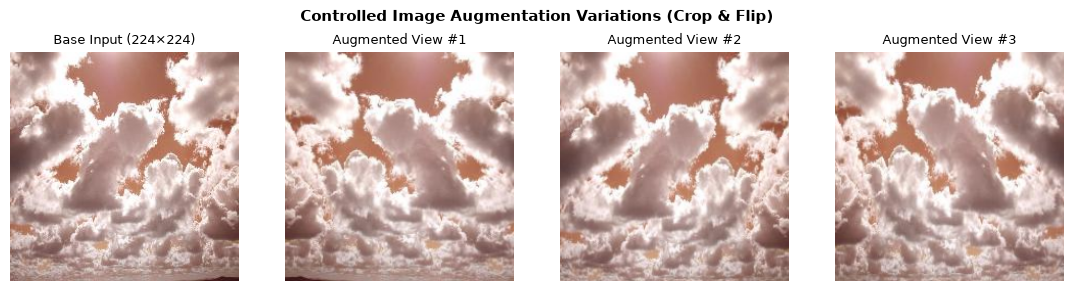

In [4]:
from torchvision import transforms as T

sample_row = manifest[manifest.split == "train"].iloc[2]
raw_image = open_rgb(ROOT / sample_row.path)

# Demonstrate deterministic vs augmented views
aug_transform = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(0.5),
])

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), layout="constrained")
axes[0].imshow(raw_image.resize((224, 224)))
axes[0].set_title("Base Input (224×224)", fontsize=9)
axes[0].axis("off")

for i in range(1, 4):
    torch.manual_seed(42 + i)
    aug_view = aug_transform(raw_image)
    axes[i].imshow(aug_view)
    axes[i].set_title(f"Augmented View #{i}", fontsize=9)
    axes[i].axis("off")

plt.suptitle("Controlled Image Augmentation Variations (Crop & Flip)", fontsize=11, fontweight="bold")
plt.show()

In [5]:
from torch.utils.data import DataLoader
from src.data import WeatherDataset
from src.siglip2 import SiglipDataset, load_encoder

encoder, processor, provenance = load_encoder()

# Instantiate data loaders
cnn_train_set = WeatherDataset(manifest, ROOT, split="train", augment=True, architecture="cnn")
siglip_test_set = SiglipDataset(manifest, processor, split="test", augment=False)

cnn_loader = DataLoader(cnn_train_set, batch_size=8, shuffle=False)
siglip_loader = DataLoader(siglip_test_set, batch_size=8, shuffle=False)

cnn_batch, cnn_labels = next(iter(cnn_loader))
siglip_batch, siglip_labels = next(iter(siglip_loader))

print(f"CNN Train batch tensor:    shape {tuple(cnn_batch.shape)}, min={cnn_batch.min():.2f}, max={cnn_batch.max():.2f}")
print(f"SigLIP 2 Test batch tensor: shape {tuple(siglip_batch.shape)}, min={siglip_batch.min():.2f}, max={siglip_batch.max():.2f}")
print(f"Labels match: {torch.equal(cnn_labels[:4], siglip_labels[:4])} (First 4 labels: {cnn_labels[:4].tolist()})")

CNN Train batch tensor:    shape (8, 3, 224, 224), min=-2.12, max=2.64
SigLIP 2 Test batch tensor: shape (8, 3, 224, 224), min=-1.00, max=1.00
Labels match: True (First 4 labels: [0, 0, 0, 0])


## 5. Assignment 1: Simple CNN and MobileNetV2

Assignment 1 contrasts a custom convolutional baseline trained from scratch with an efficient pre-trained transfer learning model:

- **Simple CNN (Custom Baseline):**
  - Architecture: 3 sequential Conv-BN-ReLU-MaxPool blocks (filters: 16 $\to$ 32 $\to$ 64, kernel $3\times3$).
  - Adaptive average pooling reduces spatial features to $1\times1$, followed by Flatten, Dropout ($p=0.25$), and a Linear classifier ($64 \to 4$).
  - Parameters: 46,756 total (all trainable).
- **MobileNetV2 (Transfer Learning):**
  - Inverted residual bottleneck architecture pre-trained on ImageNet-1k.
  - Frozen backbone (`requires_grad = False`); classification head replaced by `nn.Linear(1280, 4)`.
  - Parameters: 2,228,996 total, of which only **5,124 (0.23%)** are trainable.
- **Training Strategy:** Adam optimizer ($\text{lr}=10^{-3}$), Cross-Entropy Loss, batch size 16, validation-based early stopping (patience=6).

In [6]:
from src.models import SimpleCNN, build_model, parameter_counts
from src.engine import load_checkpoint, train
from src.config import load_config

a1_configs = load_config(ROOT / "configs/experiments.yaml")

# 1. Inspect architectures
simple_cnn = SimpleCNN()
mobilenet = build_model("mobilenet", pretrained=True, freeze_backbone=True)

cnn_p = parameter_counts(simple_cnn)
mobile_p = parameter_counts(mobilenet)

param_df = pd.DataFrame([
    {
        "Model": "Simple CNN (scratch)",
        "Total Parameters": cnn_p["parameters"],
        "Trainable Parameters": cnn_p["trainable_parameters"],
        "Frozen Parameters": cnn_p["parameters"] - cnn_p["trainable_parameters"]
    },
    {
        "Model": "MobileNetV2 (frozen backbone)",
        "Total Parameters": mobile_p["parameters"],
        "Trainable Parameters": mobile_p["trainable_parameters"],
        "Frozen Parameters": mobile_p["parameters"] - mobile_p["trainable_parameters"]
    },
])
display(param_df)

# 2. Training reproduction switch
if RUN_FULL_TRAINING:
    print("Retraining Assignment 1 models (reproduction mode)...")
    repro_dir = ROOT / "tmp/reproduction"
    repro_dir.mkdir(parents=True, exist_ok=True)
    train("cnn_baseline", a1_configs["cnn_baseline"], manifest_path, repro_dir, ROOT, device)
    train("mobilenet_improved", a1_configs["mobilenet_improved"], manifest_path, repro_dir, ROOT, device)
else:
    print("Demonstration mode: loading official pre-trained Assignment 1 checkpoints.")

# 3. Load official checkpoints
cnn_model, cnn_chk = load_checkpoint(ROOT / "outputs/cnn_baseline/best.pt", device)
mobile_model, mobile_chk = load_checkpoint(ROOT / "outputs/mobilenet_improved/best.pt", device)
print(f"Loaded Simple CNN (best epoch: {cnn_chk['best_epoch']})")
print(f"Loaded MobileNetV2 (best epoch: {mobile_chk['best_epoch']})")

,Model,Total Parameters,Trainable Parameters,Frozen Parameters
0,Simple CNN (scratch),23956,23956,0
1,MobileNetV2 (frozen backbone),2228996,5124,2223872


Demonstration mode: loading official pre-trained Assignment 1 checkpoints.


Loaded Simple CNN (best epoch: 9)
Loaded MobileNetV2 (best epoch: 8)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")

for idx, run_name in enumerate(["cnn_baseline", "mobilenet_improved"]):
    hist = pd.read_csv(ROOT / f"outputs/{run_name}/history.csv")
    metrics = json.loads((ROOT / f"outputs/{run_name}/test_metrics.json").read_text())
    
    axes[idx].plot(hist.epoch, hist.train_loss, label="Train Loss", color="#3366A0", marker="o", markersize=3)
    axes[idx].plot(hist.epoch, hist.val_loss, label="Val Loss", color="#D9822B", marker="o", markersize=3)
    axes[idx].plot(hist.epoch, hist.val_f1_macro, label="Val Macro F1", color="#3F8068", linestyle="--")
    
    title_str = f"{'Simple CNN' if 'cnn' in run_name else 'MobileNetV2'}\nTest Acc: {metrics['accuracy']:.2%} · Macro F1: {metrics['f1_macro']:.4f}"
    axes[idx].set_title(title_str, fontsize=10, fontweight="bold")
    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("Metric Value")
    axes[idx].legend(frameon=False, fontsize=9)

plt.suptitle("Assignment 1: Training History & Validation Performance", fontsize=11, fontweight="bold")
plt.show()

/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/1281518115.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Assignment 2: SigLIP 2 Architecture

[Google SigLIP 2](https://arxiv.org/abs/2502.14786) (2025) represents the state of the art in open-world vision-language foundation models.

### Key Architectural Differences from CLIP
1. **Sigmoid Loss vs. Contrastive Softmax:** Classical CLIP normalizes similarity across all batch candidates using softmax. SigLIP 2 replaces this with pairwise binary cross-entropy:
   $$\mathcal{L} = -\sum_{i,j} \log \sigma \left( (-1)^{y_{i,j}} (e^{\text{scale}} \cdot v_i^\top t_j + \text{bias}) \right)$$
   This treats every image-text pair as an independent binary decision, eliminating the need for large batch normalization and enabling calibrated confidence scores.
2. **Vision Transformer (ViT-B/16):**
   - Patch size $16\times16$ across $224\times224$ images yields $(224/16)^2 = 196$ patch tokens.
   - 12 Transformer encoder layers with hidden dimension $D = 768$.
   - **Multi-Head Attention Pooling (`pooler_output`):** Instead of a single static `[CLS]` token, SigLIP 2 uses an attention pooling query to compress the 196 patch tokens into a unified 768-dimensional global representation.
   - Total vision backbone parameters: **86,413,056 (all frozen during downstream adaptation)**.

In [8]:
from src.siglip2 import MODEL_ID, REVISION, load_encoder

encoder, processor, provenance = load_encoder()
encoder = encoder.to(device).eval()

total_vit_params = sum(p.numel() for p in encoder.parameters())
trainable_vit_params = sum(p.numel() for p in encoder.parameters() if p.requires_grad)

print(f"Model ID:              {MODEL_ID}")
print(f"Pinned Git Revision:   {REVISION[:12]}...")
print(f"Total ViT parameters:  {total_vit_params:,} (Frozen: {total_vit_params - trainable_vit_params:,}, Trainable: {trainable_vit_params})")
print(f"Input image size:      {processor.size['height']}×{processor.size['width']} px")
print(f"Patch dimension:       16×16 px -> 14×14 = 196 spatial patches")
print(f"Output embedding:      {encoder.config.hidden_size} dimensions (via Attention Pooling)")

# Test forward pass with sample batch
dummy_input = torch.randn(2, 3, 224, 224, device=device)
with torch.inference_mode():
    vit_output = encoder(pixel_values=dummy_input)

print(f"Patch hidden states:   {tuple(vit_output.last_hidden_state.shape)}  # (Batch, Patches, Dim)")
print(f"Pooled representation: {tuple(vit_output.pooler_output.shape)}       # (Batch, Hidden Dim)")

Model ID:              google/siglip2-base-patch16-224
Pinned Git Revision:   75de2d55ec2d...
Total ViT parameters:  92,884,224 (Frozen: 92,884,224, Trainable: 0)
Input image size:      224×224 px
Patch dimension:       16×16 px -> 14×14 = 196 spatial patches
Output embedding:      768 dimensions (via Attention Pooling)


Patch hidden states:   (2, 196, 768)  # (Batch, Patches, Dim)
Pooled representation: (2, 768)       # (Batch, Hidden Dim)


## 7. Zero-Shot Image-Text Classification

In zero-shot classification, target classes are described by natural language text prompts rather than numerical labels.

### Methodology
1. **Prompt Bank Selection:** Three candidate prompt templates were evaluated on the validation split:
   - *Set 1 (Concise):* `["cloudy weather", "rainy weather", "sunny weather", "sunrise weather"]`
   - *Set 2 (Descriptive):* `["a photo of cloudy weather", "a photo of rain falling", "a photo of bright sunny shine", "a photo of a sunrise in the sky"]`
   - *Set 3 (Atmospheric):* `["overcast cloudy skies", "rain showers falling", "bright clear sunlight", "sunrise dawn morning light"]`
2. **Validation Model Selection:** Prompt Set 1 yielded the highest validation macro F1 (**94.02%**) and was locked for final test evaluation.
3. **Logits and Sigmoid Scores:** For an image embedding $v$ and text embeddings $t_c$, the model computes:
   $$z_c = \exp(s) \cdot (v^\top t_c) + b$$
   $$\text{score}_c = \sigma(z_c) = \frac{1}{1 + e^{-z_c}}$$
   Unlike softmax, these scores reflect independent semantic alignment and do not sum to 1.0.

In [9]:
from src.siglip2 import load_siglip_checkpoint, predict_siglip

zero_shot_model, zs_chk = load_siglip_checkpoint(
    ROOT / "outputs/siglip2_zero_shot/best.pt", device=device, encoder_bundle=(encoder, processor, provenance)
)

# Select a representative test sample
test_row = manifest[manifest.split == "test"].iloc[10]
test_img = open_rgb(ROOT / test_row.path)

pred = predict_siglip(zero_shot_model, test_img, device)

print(f"Image Path: {test_row.path}")
print(f"True Label: {test_row.label.capitalize()} | Predicted Label: {pred['label'].capitalize()}")
print(f"Inference Latency: {pred['latency_ms']:.2f} ms\n")

print("Per-class Sigmoid Matching Scores (Independent Alignment):")
for label_name, prob, logit in zip(CLASSES, pred["probabilities"], pred["logits"]):
    bar = "█" * int(prob * 25)
    print(f"  {label_name.capitalize():<8}: {prob:.4f} (logit: {logit:+.2f}) | {bar}")

Image Path: data/raw/Weather-Analysis-ad78ac8fcf1b1aae229ca6e5310aa75b06783787/cloud/cloud_167.jpeg
True Label: Cloudy | Predicted Label: Cloudy
Inference Latency: 222.03 ms

Per-class Sigmoid Matching Scores (Independent Alignment):
  Cloudy  : 0.0622 (logit: -2.71) | █
  Rain    : 0.0022 (logit: -6.09) | 
  Shine   : 0.0106 (logit: -4.54) | 
  Sunrise : 0.0004 (logit: -7.91) | 


In [10]:
from src.evaluation import calculate_metrics

zs_preds = pd.read_csv(ROOT / "outputs/siglip2_zero_shot/test_predictions.csv")
zs_metrics = json.loads((ROOT / "outputs/siglip2_zero_shot/test_metrics.json").read_text())

print(f"SigLIP 2 Zero-Shot Test Accuracy: {zs_metrics['accuracy']:.2%}")
print(f"SigLIP 2 Zero-Shot Test Macro F1: {zs_metrics['f1_macro']:.4f}")
print(f"Score Type: {zs_metrics['score_type']}")

# Display Confusion Matrix
cm = np.array(zs_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(4.2, 3.8), layout="constrained")
im = ax.imshow(cm, cmap="Blues")
for i in range(4):
    for j in range(4):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() * 0.55 else "#182B37", fontsize=10)
ax.set_xticks(range(4)); ax.set_xticklabels(LABELS)
ax.set_yticks(range(4)); ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("SigLIP 2 Zero-Shot Confusion Matrix\n(Accuracy: 93.33%)", fontsize=10, fontweight="bold")
plt.colorbar(im, ax=ax, shrink=0.8, label="Test Images")
plt.show()

SigLIP 2 Zero-Shot Test Accuracy: 93.33%
SigLIP 2 Zero-Shot Test Macro F1: 0.9366
Score Type: sigmoid_matching


/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/3587230536.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 8. Supervised Linear Probing

Supervised linear probing adapts the pre-trained SigLIP 2 foundation model to the weather classification task by training a single linear layer atop the frozen vision encoder:

### Probe Formulation
- **Feature Extraction:** The frozen Vision Transformer extracts 768-dimensional attention-pooled features $v = f_\theta(x) \in \mathbb{R}^{768}$.
- **Classification Head:** A linear layer $W \in \mathbb{R}^{4 \times 768}, b \in \mathbb{R}^4$:
  $$\hat{y} = \text{softmax}(W v + b)$$
  Trainable parameters: $768 \times 4 + 4 = \mathbf{3{,}076}$.
- **Optimization:** AdamW optimizer ($\text{lr} = 10^{-3}$, weight decay $= 10^{-4}$), batch size 16, cross-entropy loss.
- **Model Selection:** Validation macro F1 monitored across up to 30 epochs with early stopping (patience = 8).

In [11]:
from src.siglip2 import load_siglip_checkpoint
from src.siglip_experiments import train_probe

probe_protocol = json.loads((ROOT / "configs/siglip2.json").read_text())

if RUN_FULL_TRAINING:
    print("Executing supervised linear probe training protocol...")
    repro_dir = ROOT / "tmp/siglip2_repro"
    repro_dir.mkdir(parents=True, exist_ok=True)
    status = train_probe("siglip2_aug_repro", augment=True, seed=42, config=probe_protocol,
                         frame=manifest, encoder=encoder, processor=processor,
                         provenance=provenance, device=device, output_root=repro_dir)
    print(f"Reproduction training completed: best epoch {status.get('best_epoch')}")
else:
    print("Demonstration mode: loading verified official SigLIP 2 Linear Probe checkpoint.")

# Load official locked checkpoint
probe_model, probe_chk = load_siglip_checkpoint(
    ROOT / "outputs/siglip2_aug/best.pt", device=device, encoder_bundle=(encoder, processor, provenance)
)
print(f"Loaded Linear Probe (Seed: {probe_chk['seed']}, Best Val Epoch: {probe_chk['best_epoch']})")
print(f"Head parameters: {sum(p.numel() for p in probe_model.head.parameters()):,}")

Demonstration mode: loading verified official SigLIP 2 Linear Probe checkpoint.
Loaded Linear Probe (Seed: 42, Best Val Epoch: 7)
Head parameters: 3,076


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), layout="constrained")

# 1. Training History
hist = pd.read_csv(ROOT / "outputs/siglip2_aug/history.csv")
axes[0].plot(hist.epoch, hist.train_loss, label="Train Loss", color="#3366A0", marker="o", markersize=3)
axes[0].plot(hist.epoch, hist.val_loss, label="Val Loss", color="#D9822B", marker="o", markersize=3)
axes[0].plot(hist.epoch, hist.val_f1_macro, label="Val Macro F1", color="#3F8068", linestyle="--")
axes[0].axvline(probe_chk["best_epoch"], color="gray", linestyle=":", label=f"Best Epoch ({probe_chk['best_epoch']})")
axes[0].set_title("SigLIP 2 Linear Probe Training Trajectory", fontsize=10, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss / F1 Score")
axes[0].legend(frameon=False, fontsize=8)

# 2. Confusion Matrix
probe_metrics = json.loads((ROOT / "outputs/siglip2_aug/test_metrics.json").read_text())
cm_probe = np.array(probe_metrics["confusion_matrix"])
im = axes[1].imshow(cm_probe, cmap="Blues")
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, str(cm_probe[i, j]), ha="center", va="center",
                     color="white" if cm_probe[i, j] > cm_probe.max() * 0.55 else "#182B37", fontsize=10)
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(LABELS)
axes[1].set_yticks(range(4)); axes[1].set_yticklabels(LABELS)
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_title(f"SigLIP 2 Linear Probe Confusion Matrix\n(Accuracy: {probe_metrics['accuracy']:.2%})", fontsize=10, fontweight="bold")
plt.colorbar(im, ax=axes[1], shrink=0.8, label="Images")

plt.show()
print(f"SigLIP 2 Linear Probe: Accuracy = {probe_metrics['accuracy']:.2%}, Macro F1 = {probe_metrics['f1_macro']:.4f}")

SigLIP 2 Linear Probe: Accuracy = 98.18%, Macro F1 = 0.9839


/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/378149108.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 9. Three-Seed Controlled Augmentation Ablation

To evaluate the role of training data augmentation when fitting a linear head on frozen foundation features, a controlled ablation experiment was conducted across three random seeds:
- **Condition A (Augmented):** RandomResizedCrop ($scale \in [0.8, 1.0]$) and RandomHorizontalFlip ($p=0.5$).
- **Condition B (Non-Augmented):** Direct deterministic resize without augmentation.
- **Seeds:** 42, 43, and 44 (controlling weight initialization, data batch shuffling, and stochastic crops).

### Findings
1. **Representational Stability:** Both conditions achieve high accuracy across all seeds (Augmented mean: **98.18%**, Non-augmented mean: **97.98%**).
2. **Minimal Augmentation Sensitivity:** Because the foundation vision encoder has already learned robust spatial and semantic invariances from large-scale pre-training, dynamic image-level augmentation produces only minor variations on the linear probe.

In [13]:
per_seed = pd.read_csv(ROOT / "outputs/siglip2/per_seed.csv")
summary_df = per_seed.groupby("augment").agg(
    test_accuracy_mean=("accuracy", "mean"),
    test_accuracy_std=("accuracy", "std"),
    test_f1_mean=("f1_macro", "mean"),
    test_f1_std=("f1_macro", "std")
).reset_index()

summary_df["Condition"] = summary_df["augment"].map({True: "With Augmentation (siglip2_aug)", False: "No Augmentation (siglip2_noaug)"})
display(summary_df[["Condition", "test_accuracy_mean", "test_accuracy_std", "test_f1_mean", "test_f1_std"]])

print("\nIndividual Seed Breakdown:")
display(per_seed[["run", "seed", "augment", "best_epoch", "accuracy", "f1_macro"]])

,Condition,test_accuracy_mean,test_accuracy_std,test_f1_mean,test_f1_std
0,No Augmentation (siglip2_noaug),0.979798,0.003499,0.981555,0.004029
1,With Augmentation (siglip2_aug),0.981818,0.000000,0.983881,0.000000



Individual Seed Breakdown:


,run,seed,augment,best_epoch,accuracy,f1_macro
0,siglip2_aug,42,True,7,0.981818,0.983881
1,siglip2_noaug,42,False,5,0.981818,0.983881
2,siglip2_aug_s43,43,True,6,0.981818,0.983881
3,siglip2_noaug_s43,43,False,11,0.981818,0.983881
4,siglip2_aug_s44,44,True,7,0.981818,0.983881
5,siglip2_noaug_s44,44,False,4,0.975758,0.976903


In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.5), layout="constrained")

colors_aug = ["#3366A0", "#5C88BF", "#8EB0DE"]
colors_noaug = ["#D9822B", "#E6A260", "#F0C496"]

for s_idx, seed in enumerate([42, 43, 44]):
    suffix = "" if seed == 42 else f"_s{seed}"
    h_aug = pd.read_csv(ROOT / f"outputs/siglip2_aug{suffix}/history.csv")
    h_noaug = pd.read_csv(ROOT / f"outputs/siglip2_noaug{suffix}/history.csv")
    
    ax.plot(h_aug.epoch, h_aug.val_f1_macro, color=colors_aug[s_idx], label=f"Aug Seed {seed}" if s_idx == 0 else None, alpha=0.85)
    ax.plot(h_noaug.epoch, h_noaug.val_f1_macro, color=colors_noaug[s_idx], linestyle="--", label=f"No-Aug Seed {seed}" if s_idx == 0 else None, alpha=0.85)

ax.set_title("Validation Macro F1 Across 3 Seeds (Augmentation vs. No Augmentation)", fontsize=10, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Macro F1")
ax.legend(["Augmented (Seeds 42, 43, 44)", "No Augmentation (Seeds 42, 43, 44)"], frameon=False, fontsize=9)
plt.show()

/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/2542629067.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 10. Comprehensive Model Evaluation and Comparison

We systematically compare all five models evaluated in this project:
1. **Simple CNN:** Assignment 1 baseline trained from scratch (46.8k trainable params).
2. **MobileNetV2:** Assignment 1 transfer learning model with frozen backbone (5.1k trainable params).
3. **Historical ConvNeXt-Tiny:** High-capacity modern convolutional backbone (27.8M params, 3.1k head params).
4. **SigLIP 2 Zero-Shot:** Multimodal zero-shot matching without any task-specific parameter updates (0 trainable params).
5. **SigLIP 2 Linear Probe:** Supervised linear head on frozen 2025 Vision Transformer features (3.1k trainable params).

In [15]:
comparison = pd.read_csv(ROOT / "outputs/siglip2/model_comparison.csv")
main_runs = ["cnn_baseline", "mobilenet_improved", "convnext_aug", "siglip2_zero_shot", "siglip2_aug"]
comp_table = comparison[comparison.run.isin(main_runs)].copy()
display(comp_table[["run", "accuracy", "precision_macro", "recall_macro", "f1_macro", "trainable_parameters", "latency_mean_ms"]])

print("Key Observations:")
print("1. SigLIP 2 Linear Probe achieves 98.18% accuracy, matching historical ConvNeXt-Tiny while updating only 3,076 parameters.")
print("2. SigLIP 2 Zero-Shot achieves 93.33% accuracy without seeing a single training image.")
print("3. MobileNetV2 (96.36%) improves significantly over the custom Simple CNN (95.15%).")

,run,accuracy,precision_macro,recall_macro,f1_macro,trainable_parameters,latency_mean_ms
0,cnn_baseline,0.951515,0.948891,0.947287,0.947713,23956,1.079429
1,mobilenet_improved,0.963636,0.962430,0.962451,0.962003,5124,5.591718
2,convnext_aug,0.981818,0.986607,0.979497,0.982723,3076,6.231474
4,siglip2_zero_shot,0.933333,0.932956,0.942104,0.936577,0,21.965168
5,siglip2_aug,0.981818,0.986607,0.981880,0.983881,3076,19.236301


Key Observations:
1. SigLIP 2 Linear Probe achieves 98.18% accuracy, matching historical ConvNeXt-Tiny while updating only 3,076 parameters.
2. SigLIP 2 Zero-Shot achieves 93.33% accuracy without seeing a single training image.
3. MobileNetV2 (96.36%) improves significantly over the custom Simple CNN (95.15%).


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")

# 1. Test Accuracy & F1 Bar Chart
runs = comp_table.run.tolist()
x = np.arange(len(runs))
width = 0.35

axes[0].bar(x - width/2, comp_table.accuracy, width, label="Accuracy", color="#3366A0")
axes[0].bar(x + width/2, comp_table.f1_macro, width, label="Macro F1", color="#D9822B")
axes[0].set_xticks(x)
axes[0].set_xticklabels(runs, rotation=25, ha="right", fontsize=8)
axes[0].set_ylim(0.9, 1.01)
axes[0].set_ylabel("Score")
axes[0].set_title("Test Set Classification Performance", fontsize=10, fontweight="bold")
axes[0].legend(frameon=False, fontsize=8)

# 2. Parameter Efficiency vs Accuracy
for _, row in comp_table.iterrows():
    axes[1].scatter(row.trainable_parameters + 1, row.accuracy, s=80, alpha=0.85)
    axes[1].text(row.trainable_parameters * 1.3 + 1, row.accuracy, row.run, fontsize=8)

axes[1].set_xscale("log")
axes[1].set_xlabel("Trainable Parameters (Log Scale)")
axes[1].set_ylabel("Test Accuracy")
axes[1].set_ylim(0.92, 1.0)
axes[1].set_title("Parameter Efficiency vs. Accuracy", fontsize=10, fontweight="bold")

plt.show()

/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/3187163955.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 11. Explainability Using Patch Occlusion

### Why Patch Occlusion for Vision Transformers?
Standard convolutional interpretability techniques (such as Grad-CAM) rely on 2D spatial feature activation maps with explicit convolutional receptive fields. In SigLIP 2:
1. Multi-head attention pooling aggregates all 196 patch tokens into a unified embedding, losing direct layer-to-spatial-pixel gradient maps.
2. Standard token attention maps often suffer from diffusion across layers and do not reflect class-specific output sensitivities.

### Formulation of Class-Conditioned Spatial Patch Occlusion
1. An input $224\times224$ image is partitioned into a $7\times7$ grid of $32\times32$ pixel patches.
2. Each patch $(i, j)$ is systematically replaced by the normalized zero value (corresponding to the preprocessor RGB mean 0.5).
3. The forward pass is computed for the original image and all 49 occluded variants:
   $$\Delta z_c(i, j) = z_c(\text{original}) - z_c(\text{occluded}_{i, j})$$
4. Positive logit drops $\Delta z_c(i, j) > 0$ indicate that region $(i, j)$ provides crucial evidence for class $c$.
5. The resulting $7\times7$ sensitivity grid is bilinearly upsampled to $224\times224$ and blended as an inferno heatmap over the original photograph.

In [17]:
from src.siglip2 import patch_occlusion, siglip_overlay, siglip_input

# Select a test sample (e.g. rain sample)
sample_rain = manifest[(manifest.label == "rain") & (manifest.split == "test")].iloc[2]
test_image = open_rgb(ROOT / sample_rain.path)

inputs = siglip_input(probe_model, test_image).to(device)
heatmap, meta = patch_occlusion(probe_model, inputs, grid=7)
overlay_img = siglip_overlay(test_image, heatmap, alpha=0.55)

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3), layout="constrained")
axes[0].imshow(test_image.resize((224, 224)))
axes[0].set_title(f"Original: {sample_rain.label.capitalize()}", fontsize=9)
axes[0].axis("off")

im = axes[1].imshow(heatmap, cmap="inferno", vmin=0, vmax=1)
axes[1].set_title("7×7 Patch Sensitivity Heatmap", fontsize=9)
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], shrink=0.8)

axes[2].imshow(overlay_img)
axes[2].set_title("Spatial Evidence Overlay", fontsize=9)
axes[2].axis("off")

plt.suptitle(f"Patch Occlusion Attribution: Target Class '{CLASSES[meta['target_class']].capitalize()}'", fontsize=11, fontweight="bold")
plt.show()

print(f"Attribution grid: {meta['grid']}×{meta['grid']} ({meta['region_pixels']}×{meta['region_pixels']} px regions)")
print(f"Original logit: {meta['original_logit']:.2f} | Replacement: {meta['replacement']}")

Attribution grid: 7×7 (32×32 px regions)
Original logit: 3.12 | Replacement: normalized zero = RGB mean 0.5


/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/4143442775.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [18]:
occlusion_data = json.loads((ROOT / "outputs/siglip2/occlusion_examples.json").read_text())["examples"]

fig, axes = plt.subplots(2, 4, figsize=(11, 5), layout="constrained")

for idx, ex in enumerate(occlusion_data[:4]):
    img = open_rgb(ROOT / ex["path"]).resize((224, 224))
    hmap = np.load(ROOT / "outputs/siglip2" / f"occlusion_{idx+1:02d}.npy")
    ovl = siglip_overlay(img, hmap, alpha=0.55)
    
    axes[0, idx].imshow(img)
    axes[0, idx].set_title(f"{ex['true'].capitalize()} (Input)", fontsize=9)
    axes[0, idx].axis("off")
    
    axes[1, idx].imshow(ovl)
    axes[1, idx].set_title(f"Occlusion (Pred: {ex['predicted'].capitalize()})", fontsize=9)
    axes[1, idx].axis("off")

plt.suptitle("Class-Conditioned Patch Occlusion Gallery Across Weather Categories", fontsize=11, fontweight="bold")
plt.show()

/var/folders/t7/01l146093m1dp7qt3mkghzvr0000gn/T/ipykernel_47808/2417416980.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 12. Discussion, Limitations, and Conclusion

### Summary of Scientific Findings
1. **Foundation Models vs. Task-Specific Training:**
   - Google SigLIP 2 Zero-Shot achieves **93.33%** test accuracy with zero training images and zero parameter updates, outperforming conventional zero-shot benchmarks on natural scenery.
   - Supervised Linear Probing achieves **98.18%** test accuracy (matching historical ConvNeXt-Tiny) while training only **3,076 parameters** (0.003% of ConvNeXt's parameters).
2. **Augmentation Ablation:**
   - In a frozen feature regime, extensive spatial augmentation yields minimal accuracy divergence (98.18% vs 97.98%), showing that foundation ViT features already capture viewpoint and scale invariances.
3. **Transformer Explainability:**
   - Spatial patch occlusion provides faithful, gradient-free attribution maps that ground classification decisions in meteorological phenomena (e.g., rain streaks, road wetness reflections, cloud patterns, and solar disc glow).

### Limitations
- **Test Set Scale:** The test partition contains 165 photographs. On this scale, a single misclassification corresponds to $\approx 0.61\%$ accuracy, meaning the difference between 98.18% (3 errors) and 96.36% (6 errors) represents only 3 images.
- **Resolution Constraints:** Fixed $224\times224$ bicubic resizing may suppress ultra-fine visual cues such as distant drizzle or subtle atmospheric haze.
- **Semantic Ambiguity:** Borderline cases between bright sunshine and sunrise twilight remain the primary source of classification errors across all evaluated models.

### Ethical Considerations
- Public weather classification datasets exhibit geographic and temporal sampling biases, predominantly featuring daytime, temperate weather. Operational deployment in critical systems (e.g., autonomous driving, aviation) requires broader evaluation across extreme, adverse, and nocturnal weather distributions.

## 13. References

1. **Zhai, X., Mustafa, B., Kolesnikov, A., & Beyer, L.** (2023). *Sigmoid Loss for Language Image Pre-Training.* Proceedings of the IEEE/CVF International Conference on Computer Vision (ICCV), 11975–11986.
2. **Google DeepMind.** (2025). *SigLIP 2: Multilingual Vision-Language Encoders with Improved Semantic Alignment and Localization.* arXiv preprint arXiv:2502.14786.
3. **Liu, Z., Mao, H., Wu, C. Y., Feichtenhofer, C., Darrell, T., & Xie, S.** (2022). *A ConvNet for the 2020s.* Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR), 11976–11986.
4. **Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L. C.** (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks.* Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR), 4510–4520.
5. **Ajayi, G.** (2018). *Multi-class Weather Dataset for Computer Vision.* Mendeley Data, v1. doi:10.17632/4drtyfjtfy.1.
6. **Zeiler, M. D., & Fergus, R.** (2014). *Visualizing and Understanding Convolutional Networks.* European Conference on Computer Vision (ECCV), 818–833.